In [1]:
import MITgcmutils as mit
import os
from matplotlib import pyplot as plt
import pandas as pd
import pickle
from scipy.interpolate import interp2d
import numpy as np
from scipy.interpolate import griddata
from scipy.optimize import curve_fit
from math import sin, cos, sqrt, atan2, radians
from datetime import datetime, timedelta

### Load SWOT data

In [2]:
## GS extention
with open('GSExtension_reselect.pkl', 'rb') as f:
    data = pickle.load(f)

In [6]:
# ## Sargasso Sea (Oleander)
# with open('Oleander_reselect.pkl', 'rb') as f:
#     data = pickle.load(f)

In [3]:
spectra_tot_combined = data['spectra_tot_combined']
ssha_tot_combined = data['ssha_tot_combined']
lon_strip_tot = data['lon_strip_tot']
lat_strip_tot = data['lat_strip_tot']
ssha_mean2side = data['ssha_mean2side']

In [4]:
ssha_tot_combined.keys()

Index(['month', 'position', 'dates', 'ssha2side', 'seasons', 'day_indx'], dtype='object')

In [5]:
ssha_tot_combined['dates'] = pd.to_datetime(ssha_tot_combined['dates'], format='%y/%m/%d')
ssha_tot_combined['day_of_year'] = ssha_tot_combined['dates'].dt.dayofyear

In [6]:
lon_asd = lon_strip_tot[0]-360 # an example of ascending track
lat_asd = lat_strip_tot[0]

## Load Simulation data

In [7]:
path="/resnick/groups/oceanphysics/albion/NA/run"
os.chdir(path)

In [8]:
xc = mit.rdmds('XC') # (800,2960)
yc = mit.rdmds('YC')
x = xc[0,:] # (2960,)
y = yc[:,0]
hfacw = mit.rdmds('hFacW')
hfacs = mit.rdmds('hFacS')
hfacc = mit.rdmds('hFacC')

In [9]:
max_lat = np.max([np.max(arr) for arr in lat_strip_tot])
min_lat = np.min([np.min(arr) for arr in lat_strip_tot])
max_lon = np.max([np.max(arr) for arr in lon_strip_tot])
min_lon = np.min([np.min(arr) for arr in lon_strip_tot])

x_west = min_lon - 360
x_east = max_lon - 360
y_north = max_lat
y_south = min_lat


x_west_indx = np.argmin(np.abs(x - x_west))
x_east_indx = np.argmin(np.abs(x - x_east))
y_north_indx = np.argmin(np.abs(y-y_north))
y_south_indx = np.argmin(np.abs(y-y_south))

xc_region = xc[y_south_indx:y_north_indx,x_west_indx:x_east_indx]
yc_region = yc[y_south_indx:y_north_indx,x_west_indx:x_east_indx]
hfacw_region = hfacw[0,y_south_indx:y_north_indx,x_west_indx:x_east_indx]
hfacs_region = hfacs[0,y_south_indx:y_north_indx,x_west_indx:x_east_indx]
hfacc_region = hfacc[0,y_south_indx:y_north_indx,x_west_indx:x_east_indx]

In [10]:
hfacs_region_3d = np.repeat(hfacs_region[None, :, :], 365, axis=0)
hfacw_region_3d = np.repeat(hfacw_region[None, :, :], 365, axis=0)
hfacc_region_3d = np.repeat(hfacc_region[None, :, :], 365, axis = 0)

### Functions of spectral computation and fit

In [13]:
def model_spectra(ssh_reshaped_model,track_length,dx = 2e3):
    window = np.sqrt(8./3.)*np.sin(np.pi*np.arange(track_length)/track_length)**2
    window_2d = np.broadcast_to(window.reshape(track_length, 1), (track_length, 25))
    
    ssh_reshaped_model_left = ssh_reshaped_model[:,5:30]
    ssh_reshaped_model_right = ssh_reshaped_model[:,39:39+25]
    # if np.isnan(ssh_reshaped_model_left).any() and np.isnan(ssh_reshaped_model_right).any(): 
    #     print("error, recheck selection")
        # continue 
    results = []
    for oneswath in [ssh_reshaped_model_left,ssh_reshaped_model_right]:
        if np.all(np.isnan(oneswath)):
            print('nan swath')
            continue   # skip this array
        windowed_full = oneswath * window_2d
        amp_full = np.fft.rfft(windowed_full,axis=0)# rfft applied to windowed ssh [sample,y/2,x]
        ampsq_full = dx*(np.abs(amp_full))**2/track_length
        ampsq_1side_full = np.empty(ampsq_full.shape)
        ampsq_1side_full[:]=np.nan
        ampsq_1side_full[1:,:]=2*ampsq_full[1:,:]
        ampsq_1side_full[0,:] = ampsq_full[0,:]
        result = np.nanmean(ampsq_1side_full,axis = 1)#axis=tuple([0,2]))
        results.append(result)
    spec_1side_full = np.mean(results, axis=0)
    return spec_1side_full

In [14]:
track_length = lon_strip_tot[0].shape[0]
dx = 2e3
k = np.fft.rfftfreq(track_length, dx)# rfft wave number cpm

In [15]:
def balanced_fit(k,A,k0,s0): # for balanced part fixed plateau
    return A/(1 + (k/k0)**(s0))

def matern_spec_new(k,s,A_s): # for small-scale part
    return 2*np.pi*A_s/((1+(100e3*k)**2)**(s/2))

def F_new(k,A,k0,s0,s,A_s):
    return np.log(balanced_fit(k,A,k0,s0)+ matern_spec_new(k,s,A_s)) # fixed plateau

def F_balanced(k,A,k0,s0):
    return np.log(balanced_fit(k,A,k0,s0)) # fixed plateau

In [19]:
#initial guesses
k0init = 8e-6
s0init = 5
pinit = 1

ss = 1.2
As0 = 0.5

In [20]:
wnew = np.sqrt(k[1:])

In [21]:
def derx(a, dx):
    ax = np.ma.zeros(a.shape) # a(x,y)
    ax[0,:] = (-a[2,:] + 4*a[1,:] - 3*a[0,:])/(2*dx)
    ax[1:-1,:] = (a[2:,:] - a[:-2,:])/(2*dx)
    ax[-1,:] = (3*a[-1,:] - 4*a[-2,:] + a[-3,:])/(2*dx)
    return ax

def dery(a, dy):
    ay = np.ma.zeros(a.shape)
    ay[:,0] = (-a[:,2] + 4*a[:,1] - 3*a[:,0])/(2*dy)
    ay[:,1:-1] = (a[:,2:] - a[:,:-2])/(2*dy)
    ay[:,-1] = (3*a[:,-1] - 4*a[:,-2] + a[:,-3])/(2*dy)
    return ay

In [22]:
g = 9.81
dx = 2e3
dy = 2e3

#### load daily averaged ssh from simulation

In [23]:
## computed and saved in simulation_data.ipynb
# etabar_daily = np.load('/home/xihanz/my-jupyter-notebooks/etadaily_simulation.npy')
etabar_daily = np.load('/home/xihanz/my-jupyter-notebooks/etasnapshots_simulation.npy') # check simulation snapshots

In [24]:
# SSHA from time and spatial mean in simulation (regional)
eta_daily_region = etabar_daily[:,y_south_indx:y_north_indx,x_west_indx:x_east_indx]
eta_daily_region[hfacc_region_3d == 0] = np.nan
anualmean_region = np.mean(eta_daily_region,axis = 0)
eta_anom_region = eta_daily_region - anualmean_region[None,:,:]

eta_spatialmean = np.nanmean(eta_anom_region,axis = tuple((1,2))) # Spatial average of selected region
eta_spanom_region = eta_anom_region - eta_spatialmean[:,None,None]

#### interoplate the simulation SSHA to SWOT grid and compute the spectra

In [32]:
spectra_simulation = np.zeros((ssha_tot_combined.shape[0],track_length//2 + 1))
track_ssh_reshaped_sim = np.zeros((ssha_tot_combined.shape[0],lon_asd.shape[0],lon_asd.shape[1]))
# for i, row in ssha_tot_combined.iloc[:1].iterrows():
for i, row in ssha_tot_combined.iterrows():
    print(i,row['position'])
    dayofyear = row['day_of_year']
    if dayofyear > 365:
        continue
    day_indx = int(row['day_indx'])
    lon_swot = lon_strip_tot[day_indx]-360
    lat_swot = lat_strip_tot[day_indx]
    ssha2side_swot = row['ssha2side']
    eta_snap = np.squeeze(eta_spanom_region[dayofyear-1,:,:])
    # eta_snap = np.squeeze(eta_daily_region[dayofyear-1,:,:])
    track_ssh = griddata(
            (xc_region.flatten(), yc_region.flatten()),  # points (longitude, latitude)
            eta_snap.flatten(),  # values (model SSH data)
            (lon_swot.flatten(), lat_swot.flatten()),  # query points (longitude, latitude mesh)
            method='linear'  # Interpolation method ('linear', 'nearest', 'cubic')
        )
    track_ssh_reshaped = track_ssh.reshape(lon_swot.shape)
    track_ssh_reshaped[np.isnan(ssha2side_swot)] = np.nan
    track_ssh_reshaped_sim[i,:,:] = track_ssh_reshaped
    
    spectra_simulation[i,:] = model_spectra(track_ssh_reshaped,track_length)   
    # print(i,row['day_of_year'],row['day_indx'])

ssha_tot_combined['spectra_simulation'] = list(spectra_simulation)
ssha_tot_combined['track_ssh_sim'] = list(track_ssh_reshaped_sim)

0 201.0
nan swath
1 201.0
nan swath
2 201.0
nan swath
3 201.0
nan swath
4 201.0
5 201.0
nan swath
6 201.0
nan swath
7 201.0
8 201.0
nan swath
9 201.0
10 201.0
nan swath
11 201.0
nan swath
12 201.0
nan swath
13 201.0
nan swath
14 201.0
15 201.0
nan swath
16 214.0
nan swath
17 214.0
nan swath
18 214.0
nan swath
19 214.0
nan swath
20 214.0
nan swath
21 214.0
nan swath
22 214.0
nan swath
23 214.0
24 214.0
nan swath
25 214.0
nan swath
26 214.0
27 214.0
nan swath
28 214.0
nan swath
29 214.0
nan swath
30 214.0
nan swath
31 214.0
nan swath
32 214.0
nan swath
33 214.0
nan swath
34 229.0
nan swath
35 229.0
nan swath
36 229.0
nan swath
37 229.0
nan swath
38 229.0
nan swath
39 229.0
nan swath
40 229.0
41 229.0
42 229.0
nan swath
43 229.0
nan swath
44 229.0
nan swath
45 229.0
46 229.0
47 229.0
nan swath
48 229.0
nan swath
49 229.0
nan swath
50 229.0
nan swath
51 229.0
nan swath
52 229.0
nan swath
53 257.0
nan swath
54 257.0
nan swath
55 257.0
56 257.0
57 257.0
nan swath
58 257.0
59 257.0
60 257.0
6

#### save the SSHA spectra from the simulation (daily mean)

In [35]:
# with open('/home/xihanz/my-jupyter-notebooks/GSExtension_reselect_sim.pkl', 'wb') as f:
#     pickle.dump({'spectra_tot_combined': spectra_tot_combined, 'ssha_tot_combined': ssha_tot_combined, \
#                  'lon_strip_tot': lon_strip_tot, 'lat_strip_tot': lat_strip_tot,'ssha_mean2side':ssha_mean2side}, f)


# with open('/home/xihanz/my-jupyter-notebooks/Oleander_reselect_sim.pkl', 'wb') as f:
#     pickle.dump({'spectra_tot_combined': spectra_tot_combined,'ssha_tot_combined': ssha_tot_combined,\
#                 'lon_strip_tot': lon_strip_tot, 'lat_strip_tot': lat_strip_tot,'ssha_mean2side':ssha_mean2side}, f)

#### save the SSHA spectra from the simulation (snapshots)

In [2]:
# with open('/home/xihanz/my-jupyter-notebooks/GSExtension_reselect_sim_snapshots.pkl', 'wb') as f:
#     pickle.dump({'spectra_tot_combined': spectra_tot_combined, 'ssha_tot_combined': ssha_tot_combined, \
#                  'lon_strip_tot': lon_strip_tot, 'lat_strip_tot': lat_strip_tot,'ssha_mean2side':ssha_mean2side}, f)


# with open('/home/xihanz/my-jupyter-notebooks/Oleander_reselect_sim_snapshots.pkl', 'wb') as f:
#     pickle.dump({'spectra_tot_combined': spectra_tot_combined,'ssha_tot_combined': ssha_tot_combined,\
#                 'lon_strip_tot': lon_strip_tot, 'lat_strip_tot': lat_strip_tot,'ssha_mean2side':ssha_mean2side}, f)

#### load the SSHA spectra from the simulation (daily mean) 

In [28]:
# with open('/home/xihanz/my-jupyter-notebooks/Oleander_reselect_sim.pkl', 'rb') as f:
#     data = pickle.load(f)
# ssha_tot_combined = data['ssha_tot_combined']

with open('/home/xihanz/my-jupyter-notebooks/GSExtension_reselect_sim.pkl', 'rb') as f:
    data = pickle.load(f)
ssha_tot_combined = data['ssha_tot_combined']

In [29]:
data.keys()

dict_keys(['spectra_tot_combined', 'ssha_tot_combined', 'lon_strip_tot', 'lat_strip_tot', 'ssha_mean2side'])

In [30]:
mean_spectrum = np.mean(np.stack(spectra_tot_combined['spectrum'].values), axis=0)

Text(0, 0.5, 'power spectral density (cm$^{2}$ cpkm$^{-1}$)')

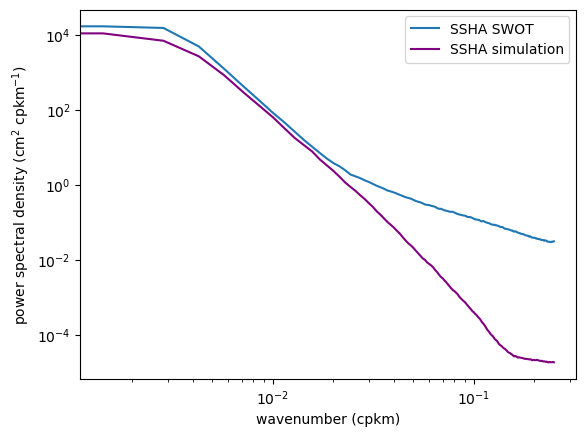

In [31]:
plt.loglog(k*1e3,mean_spectrum,label = 'SSHA SWOT')
plt.loglog(k*1e3,np.mean(ssha_tot_combined['spectra_simulation'],axis = 0),label = 'SSHA simulation',color = 'purple')
# plt.loglog(k*1e3,mean_spectrum_sim,label = 'SSHA simulation',color = 'purple')
# plt.loglog(k*1e3,np.mean(spectra_simulation,axis = 0),label = 'SSHA simulation',color = 'purple')
plt.legend()
# plt.ylim((1e-2,1e5))
# plt.ylim((1e-6,1e5))
plt.xlabel('wavenumber (cpkm)')
plt.ylabel('power spectral density (cm$^{2}$ cpkm$^{-1}$)')

#### fit the time-mean spectrum from simulation 

In [32]:
simulation_mean = np.mean(ssha_tot_combined['spectra_simulation'],axis = 0)
Ainit = simulation_mean[1]

In [34]:
fitk = 35
modelcoef,modelcov = curve_fit(F_balanced, k[1:fitk], np.log(simulation_mean[1:fitk]), \
                                p0 = [Ainit,k0init,s0init],sigma = np.sqrt(k[1:fitk]), absolute_sigma=True,\
                                bounds=([0, 0, 0], \
                                     [1e9, 1e9, 1e9]),maxfev=5000)
# modelcoef,modelcov = curve_fit(F_balanced, k[1:fitk], np.log(simulation_mean[1:fitk]), \
#                                 p0 = [Ainit,k0init,s0init,pinit],sigma = np.sqrt(k[1:fitk]), absolute_sigma=True,\
#                                 bounds=([0, 0, 0, 0], \
#                                      [1e9, 1e9, 1e9, 1e9]),maxfev=5000)

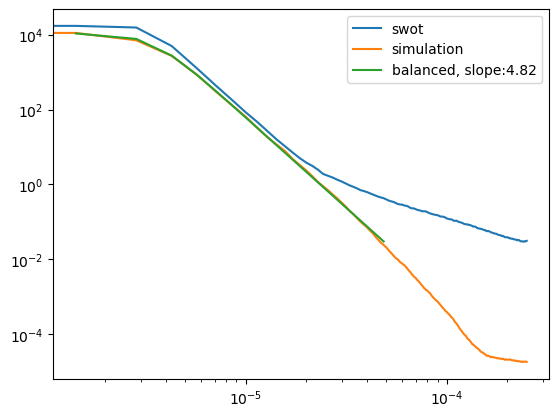

In [35]:
plt.loglog(k,mean_spectrum,label = 'swot')
plt.loglog(k,np.mean(ssha_tot_combined['spectra_simulation'],axis = 0),label = 'simulation')
plt.loglog(k[1:fitk],balanced_fit(k[1:fitk],*modelcoef),label = f'balanced, slope:{modelcoef[2]:.2f}')
plt.legend()

In [36]:
seasonal = {
    'Winter': [12, 1, 2],
    'Spring': [3, 4, 5],
    'Summer': [6, 7, 8],
    'Fall':   [9, 10, 11]
}


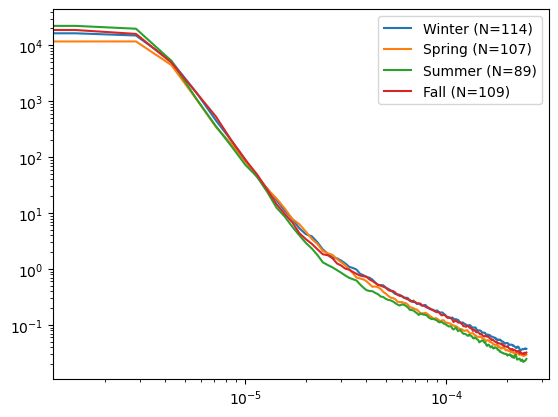

In [38]:
for season, months in seasonal.items():
    df_season = spectra_tot_combined[spectra_tot_combined['month'].isin(months)]
    # df_season = filtered_spectra[filtered_spectra['month'].isin(months)]
    if not df_season.empty:
        # Stack spectra and compute mean
        seasonal_mean = np.mean(np.vstack(df_season['spectrum'].values), axis=0)
        plt.loglog(k, seasonal_mean, label=f"{season} (N={len(df_season)})")
plt.legend()

### Monthly fit

In [40]:
def slope_estimate_monthly_full(pd_dataframe, k, initguess = [8e-06, 5, 1.2, 0.5]):#initguess = [8e-06, 5, 1, 1.2, 0.5]):
    slopemonthly = np.empty((12,))
    slopemonthly[:] = np.nan 
    unctmonthly = np.empty((12,))
    unctmonthly[:] = np.nan
    coeftot = np.empty((12,5))
    coeftot[:] = np.nan
    for month, spectrum in pd_dataframe.items():
        Ainit = spectrum[1]
        p0 = Ainit+initguess
        try:
            coef,covn = curve_fit(F_new, k[1:], np.log(spectrum[1:]), \
                                p0 ,sigma = wnew, absolute_sigma=True,\
                                bounds=([0, 0, 0, 0, 0], \
                                        [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)
            slopemonthly[int(month)-1] = coef[2] #+ coef[3]
            unctmonthly[int(month)-1] = np.sqrt(covn[2,2])#+covn[3,3])
            coeftot[int(month)-1,:] = coef
        except Exception:
            continue  # Skip to the next iteration if curve_fit fails
    return slopemonthly,unctmonthly,coeftot

In [41]:
monthly_mean_swot = spectra_tot_combined.groupby('month')['spectrum'].apply(
    lambda x: np.mean(np.stack(x), axis=0)
)

monthly_mean_simulation = ssha_tot_combined.groupby('month')['spectra_simulation'].apply(
    lambda x: np.mean(np.stack(x), axis = 0)
)

In [42]:
slopemonthly = np.empty((12,))
slopemonthly[:] = np.nan 
unctmonthly = np.empty((12,))
unctmonthly[:] = np.nan
coeftot = np.empty((12,5))
coeftot[:] = np.nan
for month, spectrum in monthly_mean_swot.items():
    Ainit = spectrum[1]
    try:
        coef,covn = curve_fit(F_new, k[1:], np.log(spectrum[1:]), \
                            p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                            bounds=([0, 0, 0, 0, 0], \
                                    [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)
        slopemonthly[int(month)-1] = coef[2] #+ coef[3]
        unctmonthly[int(month)-1] = np.sqrt(covn[2,2])#+covn[3,3])
        coeftot[int(month)-1,:] = coef
    except Exception:
        continue  # Skip to the next iteration if curve_fit fails

In [43]:
slopemonthly_sim = np.empty((12,))
slopemonthly_sim[:] = np.nan 
unctmonthly_sim = np.empty((12,))
unctmonthly_sim[:] = np.nan
coeftot_sim = np.empty((12,3))
coeftot_sim[:] = np.nan
for month, spectrum in monthly_mean_simulation.items():
    Ainit = spectrum[1]
    try:
        coef,covn = curve_fit(F_balanced, k[1:fitk], np.log(spectrum[1:fitk]), \
                            p0 = [Ainit,k0init,s0init],sigma = np.sqrt(k[1:fitk]), absolute_sigma=True,\
                            bounds=([0, 0, 0], \
                                    [1e9, 1e9, 1e9]),maxfev=5000)
        slopemonthly_sim[int(month)-1] = coef[2] #+ coef[3]
        unctmonthly_sim[int(month)-1] = np.sqrt(covn[2,2])#+covn[3,3])
        coeftot_sim[int(month)-1,:] = coef
    except Exception:
        continue  # Skip to the next iteration if curve_fit fails

In [44]:
months_idx = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul','Aug','Sept','Oct','Nov','Dec']

(3.2, 6.5)

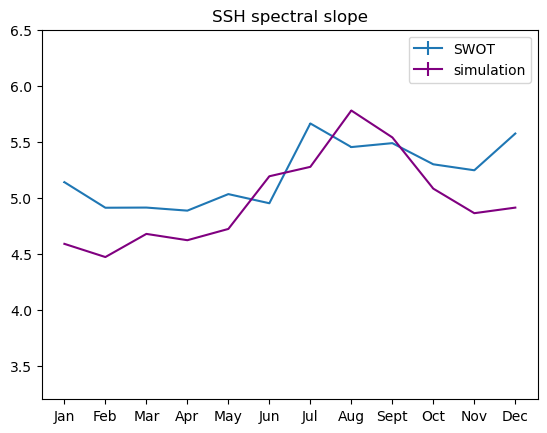

In [45]:
plt.errorbar(range(1,13),slopemonthly,2*unctmonthly,ls='-',label = 'SWOT')
plt.errorbar(range(1,13),slopemonthly_sim,2*unctmonthly_sim,ls='-',color = 'purple',label = 'simulation')
plt.legend()
plt.xticks(range(1,13),months_idx)
plt.title('SSH spectral slope')
plt.ylim((3.2,6.5))

Text(0.5, 1.0, 'month 11')

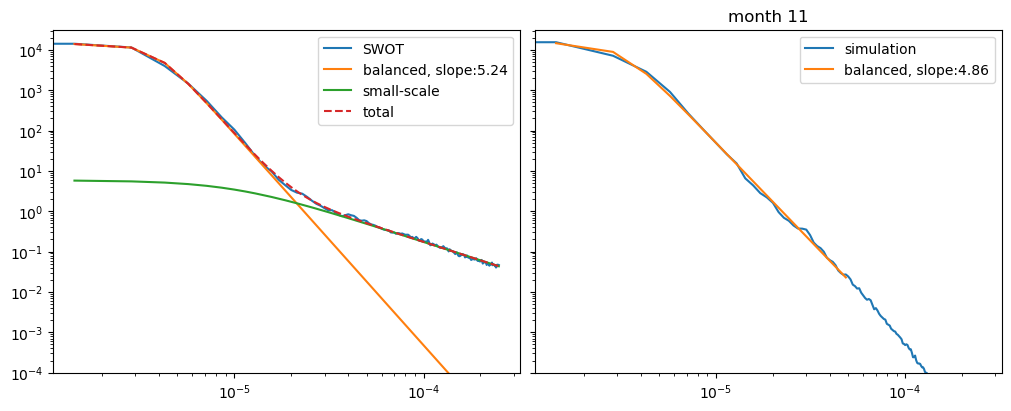

In [46]:
m = 10
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(10, 4), constrained_layout=True)
ax[0].loglog(k,monthly_mean_swot.values[m],label = 'SWOT')
ax[0].loglog(k[1:],balanced_fit(k[1:],*coeftot[m,0:3]),label = f'balanced, slope:{(coeftot[m,2]):.2f}')
ax[0].loglog(k[1:],matern_spec_new(k[1:],*coeftot[m,3:]),label = 'small-scale')
ax[0].loglog(k[1:],balanced_fit(k[1:],*coeftot[m,0:3])+matern_spec_new(k[1:],*coeftot[m,3:]),'--',label = 'total')
ax[0].legend()

ax[1].loglog(k,monthly_mean_simulation.values[m],label = 'simulation')
ax[1].loglog(k[1:fitk],balanced_fit(k[1:fitk],*coeftot_sim[m,:]),label = f'balanced, slope:{(coeftot_sim[m,2]):.2f}')

ax[1].legend()
plt.ylim([1e-4,10**4.5])
plt.title('month '+str(m+1))
# plt.savefig('/home/xihanz/my-jupyter-notebooks/Oleander_plateau.png')

#### save monthly slope and mixed layer depth 

In [47]:
mld_daily_GSextension = np.load('/home/xihanz/my-jupyter-notebooks/MLD_simulation_GSextension_reselect.npy')
# mld_daily_Oleander = np.load('/home/xihanz/my-jupyter-notebooks/MLD_simulation_Oleander_reselect.npy')

In [48]:
# shift the date of mixed layer in the simulation
# Known info
filenub0 = 7073572          # first file/iteration
ts = 45         # filename step between hourly files
n_days = 365
# nx, ny = 800, 2960
start_dt = datetime(2025, 12, 6, 14,29)   # the true time of filenub0
dates = []  # date label for each daily mean

for day in range(n_days):
    # print(day)
    dates.append((start_dt + timedelta(days=day+1)).date())

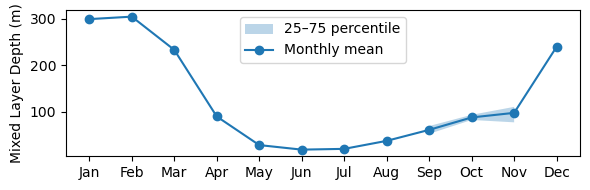

In [49]:
# mld_daily_spmean = np.nanmean(mld_daily_Oleander, axis=(1, 2))  # (365,)
mld_daily_spmean = np.nanmean(mld_daily_GSextension, axis=(1, 2))  # (365,)
# 2) make a time series
t = pd.to_datetime(dates)  # dates can be datetime.date objects
mld = pd.Series(mld_daily_spmean, index=pd.to_datetime(dates))

# 3) monthly mean time series
mld_monthly_clim = mld.groupby(mld.index.month).mean()
# (use "M" if you prefer month-end timestamps)
mld_monthly_p25  = mld.groupby(mld.index.month).quantile(0.25)
mld_monthly_p75  = mld.groupby(mld.index.month).quantile(0.75)
# Plot
fig, ax = plt.subplots(figsize=(6,2))


# percentile shading
ax.fill_between(
    months,
    mld_monthly_p25.reindex(months).values,
    mld_monthly_p75.reindex(months).values,
    alpha=0.3,
    label='25–75 percentile'
)


ax.plot(mld_monthly_clim.index,
        mld_monthly_clim.values,
        marker='o',
       label='Monthly mean')

ax.set_xticks(range(1,13))
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                    'Jul','Aug','Sep','Oct','Nov','Dec'])

ax.set_ylabel('Mixed Layer Depth (m)')
ax.legend()
# ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [50]:
mld_monthly_mean = []
mld_monthly_p25 = []
mld_monthly_p75 = []
mld_monthly_p5 = []
mld_monthly_p95 = []

dates_pd = pd.to_datetime(dates)
months = dates_pd.month

for mm in range(1, 13):
    data_month = mld_daily_GSextension[months == mm, :, :]
    # data_month = mld_daily_Oleander[months == mm, :, :]
    mld_monthly_mean.append(np.nanmean(data_month))
    mld_monthly_p25.append(np.nanpercentile(data_month, 25))
    mld_monthly_p75.append(np.nanpercentile(data_month, 75))
    mld_monthly_p5.append(np.nanpercentile(data_month, 5))
    mld_monthly_p95.append(np.nanpercentile(data_month, 95))

mld_monthly_mean = np.array(mld_monthly_mean)
mld_monthly_p25 = np.array(mld_monthly_p25)
mld_monthly_p75 = np.array(mld_monthly_p75)
mld_monthly_p5 = np.array(mld_monthly_p5)
mld_monthly_p95 = np.array(mld_monthly_p95)

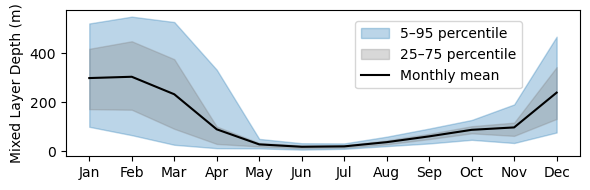

In [51]:
months_plot = np.arange(1, 13)

fig, ax = plt.subplots(figsize=(6, 2))

ax.fill_between(months_plot, mld_monthly_p5, mld_monthly_p95,color='C0',
                alpha=0.3, label='5–95 percentile')

ax.fill_between(months_plot, mld_monthly_p25, mld_monthly_p75,color='C7',
                alpha=0.3, label='25–75 percentile')

ax.plot(months_plot, mld_monthly_mean,color = 'black', #marker='o',
         label='Monthly mean')

ax.set_xticks(months_plot)
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                    'Jul','Aug','Sep','Oct','Nov','Dec'])

ax.set_ylabel('Mixed Layer Depth (m)')
ax.legend(loc='upper right', bbox_to_anchor=(0.9, 0.97))
plt.tight_layout()
plt.show()

### save monthly slope and mld

In [53]:
# # save for the Oleander monthly slope
# d = {'months_idx': months_idx, 'slopemonthly_Ol': slopemonthly,'unctmonthly_Ol':unctmonthly, \
#      'slopemonthly_sim_Ol': slopemonthly_sim, 'unctmonthly_sim_Ol': unctmonthly_sim,'mld_monthly_clim_Ol':mld_monthly_clim,\
#     'mld_monthly_Ol_p5':mld_monthly_p5,'mld_monthly_Ol_p95':mld_monthly_p95,\
#     'mld_monthly_Ol_p25':mld_monthly_p25,'mld_monthly_Ol_p75':mld_monthly_p75}
# np.save('/home/xihanz/my-jupyter-notebooks/Oleander_monthlyslope_reselect.npy', d)

# # save for the GS extension monthly slope
# d = {'months_idx': months_idx, 'slopemonthly_GS': slopemonthly,'unctmonthly_GS':unctmonthly, \
#      'slopemonthly_sim_GS': slopemonthly_sim, 'unctmonthly_sim_GS': unctmonthly_sim,'mld_monthly_clim_GS':mld_monthly_clim,\
#     'mld_monthly_GS_p5':mld_monthly_p5,'mld_monthly_GS_p95':mld_monthly_p95,\
#     'mld_monthly_GS_p25':mld_monthly_p25,'mld_monthly_GS_p75':mld_monthly_p75}
# np.save('/home/xihanz/my-jupyter-notebooks/GSExtension_monthlyslope_reselect.npy', d)

### save monthly slope and mld (Snapshots)

In [53]:
# # save for the Oleander monthly slope
# d = {'months_idx': months_idx, 'slopemonthly_Ol': slopemonthly,'unctmonthly_Ol':unctmonthly, \
#      'slopemonthly_sim_Ol': slopemonthly_sim, 'unctmonthly_sim_Ol': unctmonthly_sim,'mld_monthly_clim_Ol':mld_monthly_clim,\
#     'mld_monthly_Ol_p5':mld_monthly_p5,'mld_monthly_Ol_p95':mld_monthly_p95,\
#     'mld_monthly_Ol_p25':mld_monthly_p25,'mld_monthly_Ol_p75':mld_monthly_p75}
# np.save('/home/xihanz/my-jupyter-notebooks/Oleander_monthlyslope_reselect_snapshot.npy', d)

# # save for the GS extension monthly slope
# d = {'months_idx': months_idx, 'slopemonthly_GS': slopemonthly,'unctmonthly_GS':unctmonthly, \
#      'slopemonthly_sim_GS': slopemonthly_sim, 'unctmonthly_sim_GS': unctmonthly_sim,'mld_monthly_clim_GS':mld_monthly_clim,\
#     'mld_monthly_GS_p5':mld_monthly_p5,'mld_monthly_GS_p95':mld_monthly_p95,\
#     'mld_monthly_GS_p25':mld_monthly_p25,'mld_monthly_GS_p75':mld_monthly_p75}
# np.save('/home/xihanz/my-jupyter-notebooks/GSExtension_monthlyslope_reselect_snapshots.npy', d)

### load for KE spectra (daily mean) 
##### (_rotate is computed from simulation_data_KEspectra.ipynb to have simulation velocities rotated to the direction of SWOT)

In [47]:
# # load for GS extension region time-mean 
# KEsimspectra = np.load('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_GSextension_new_swath_reselect_rotate.npy',allow_pickle='TRUE').item()
# for key, value in KEsimspectra.items():
#     globals()[key] = value

# load for Oleander region time-mean
KEsimspectra = np.load('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_Oleander_new_swath_reselect_rotate.npy',allow_pickle='TRUE').item()
for key, value in KEsimspectra.items():
    globals()[key] = value

### load for KE spectra (daily snapshots)

In [30]:
# # load for GS extension region daily snapshots
# KEsimspectra = np.load('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_GSextension_new_swath_reselect_snapshots_rotate.npy',allow_pickle='TRUE').item()
# for key, value in KEsimspectra.items():
#     globals()[key] = value

# # load for Oleander region daily snapshots
# KEsimspectra = np.load('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_Oleander_new_swath_reselect_snapshots_rotate.npy',allow_pickle='TRUE').item()
# for key, value in KEsimspectra.items():
#     globals()[key] = value

In [48]:
# KE_spectra_sim = 0.5*(u_spectra_sim + v_spectra_sim)
# KE_spectra_sim = 0.5*(u_along_spectra_sim_sp + v_cross_spectra_sim_sp)
KE_spectra_sim = v_cross_spectra_sim
ssha_tot_combined['KE_spectra_sim'] = list(KE_spectra_sim)

### Geostrophic KE

In [53]:
geoKE_spect_sim = np.zeros((ssha_tot_combined.shape[0],track_length//2 + 1))
for i, row in ssha_tot_combined.iterrows():
    # print(i)
    day_indx = int(row['day_indx'])
    lat_swot = lat_strip_tot[day_indx]
    f = 2*np.pi*np.sin(2*np.pi*lat_swot/360)/(12*3600)
    ssh_spect_sim = row['spectra_simulation']
    geoKE_spect_sim[i,:] = (g/np.mean(f))**2*ssh_spect_sim*k**2

In [55]:
geoKE_spect_swot = np.zeros((spectra_tot_combined.shape[0],track_length//2 + 1))
for i, row in spectra_tot_combined.iterrows():
    # day_indx = int(row['day_indx'])
    # lat_swot = lat_strip_tot[day_indx]
    # f = 2*np.pi*np.sin(2*np.pi*lat_swot/360)/(12*3600)
    f = 2*np.pi*np.sin(2*np.pi*40/360)/(12*3600)
    ssh_spect = row['spectrum']
    geoKE_spect_swot[i,:] = (g/np.mean(f))**2*ssh_spect*k**2

In [56]:
spectra_tot_combined['geoKE_spect_swot'] = list(geoKE_spect_swot)

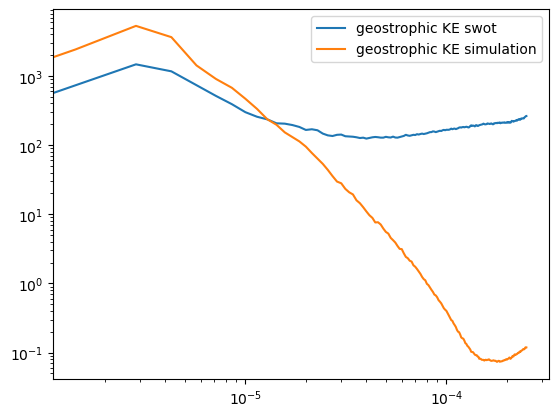

In [59]:
meanspectswot = np.mean(spectra_tot_combined['spectrum'],axis = 0)
meanspectsim = np.mean(ssha_tot_combined['spectra_simulation'],axis = 0)
plt.loglog(k,0.5*(2*np.pi)**2*(g/np.mean(f))**2*meanspectswot*k**2,label = 'geostrophic KE swot')
plt.loglog(k,0.5*(2*np.pi)**2*(g/np.mean(f))**2*meanspectsim*k**2,label = 'geostrophic KE simulation')
plt.legend()

In [60]:
for season, months in seasonal.items():
    print(season,months)

Winter [12, 1, 2]
Spring [3, 4, 5]
Summer [6, 7, 8]
Fall [9, 10, 11]


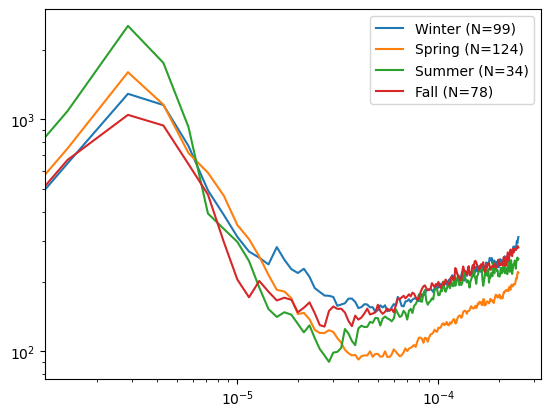

In [61]:
for season, months in seasonal.items():
    df_season = spectra_tot_combined[spectra_tot_combined['month'].isin(months)]
    # df_season = filtered_spectra[filtered_spectra['month'].isin(months)]
    if not df_season.empty:
        # Stack spectra and compute mean
        seasonal_mean = np.mean(np.vstack(df_season['geoKE_spect_swot'].values), axis=0)
        plt.loglog(k, 0.5*(2*np.pi)**2*seasonal_mean, label=f"{season} (N={len(df_season)})")
plt.legend()